# K-최근접 이웃 알고리즘(KNeighborsClassifier)
* 사이킷런에 포함된 기계학습 모델
* 알고리즘 아이디어 <br>
  - 학습한 데이터에서 가장 가까운 이웃을 보고 분류
  - 기본 5개의 이웃을 보고 결정.
  - n_neighbors(하이퍼파라미터)를 이용하여 이웃의 갯수 변경 가능<br>

※ 사이킷런(scikit-learn): 파이썬에서 가장 널리 사용되는 대표적인 오픈소스 머신러닝 라이브러리<br>
 [사이킷런 공식 사이트](https://scikit-learn.org/stable/)<br>
※ 하이퍼파라미터란? 모델링할 때 **사용자가 직접 세팅해주는 값**<br>



## 데이터 준비 + 데이터분석(시각화)

### 도미 데이터 준비하기

In [6]:
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

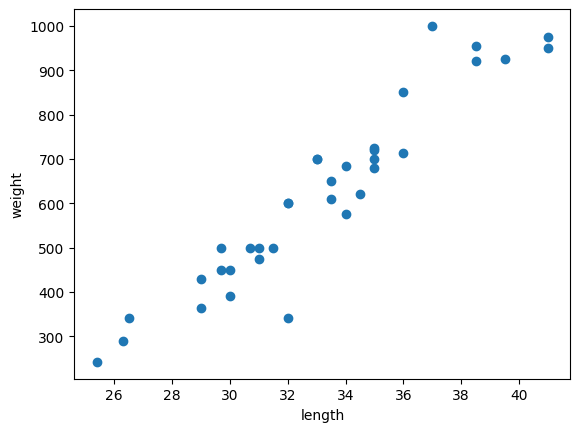

In [10]:
# 산점도 그래프로 그려보자
import matplotlib.pyplot as plt

plt.scatter(bream_length, bream_weight)
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

### 빙어 데이터 준비하기

In [8]:
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

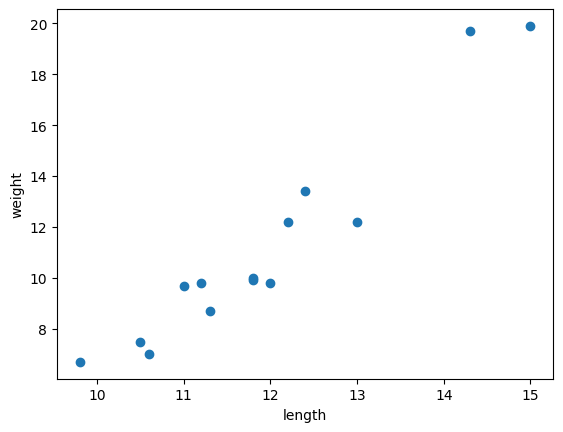

In [11]:
# 산점도 그래프로 그려보자
import matplotlib.pyplot as plt

plt.scatter(smelt_length, smelt_weight)
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

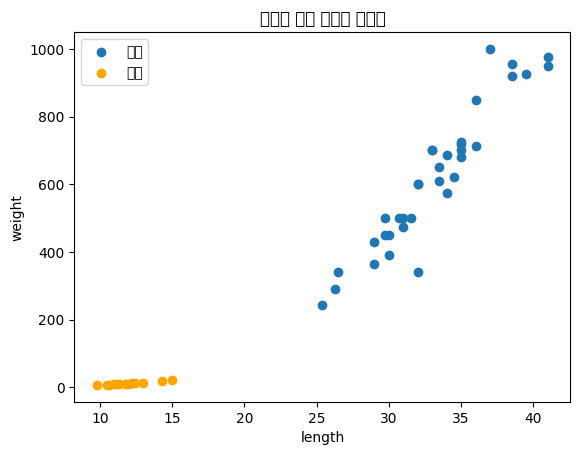

In [15]:
import matplotlib.pyplot as plt

plt.scatter(bream_length, bream_weight, label='도미')
plt.scatter(smelt_length, smelt_weight, label='빙어', color='orange')
plt.xlabel('length')
plt.ylabel('weight')
plt.title('도미와 빙어 데이터 산점도')
plt.legend()
plt.show()

## 첫번째 머신러닝 프로그램

### 데이터셋 만들기

In [12]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

In [18]:
fish_data = [[l, w] for l, w in zip(length, weight)]

print(fish_data)

[[25.4, 242.0], [26.3, 290.0], [26.5, 340.0], [29.0, 363.0], [29.0, 430.0], [29.7, 450.0], [29.7, 500.0], [30.0, 390.0], [30.0, 450.0], [30.7, 500.0], [31.0, 475.0], [31.0, 500.0], [31.5, 500.0], [32.0, 340.0], [32.0, 600.0], [32.0, 600.0], [33.0, 700.0], [33.0, 700.0], [33.5, 610.0], [33.5, 650.0], [34.0, 575.0], [34.0, 685.0], [34.5, 620.0], [35.0, 680.0], [35.0, 700.0], [35.0, 725.0], [35.0, 720.0], [36.0, 714.0], [36.0, 850.0], [37.0, 1000.0], [38.5, 920.0], [38.5, 955.0], [39.5, 925.0], [41.0, 975.0], [41.0, 950.0], [9.8, 6.7], [10.5, 7.5], [10.6, 7.0], [11.0, 9.7], [11.2, 9.8], [11.3, 8.7], [11.8, 10.0], [11.8, 9.9], [12.0, 9.8], [12.2, 12.2], [12.4, 13.4], [13.0, 12.2], [14.3, 19.7], [15.0, 19.9]]


In [19]:
 # 정답 만들
 # 1: 도미(35개), 0: 빙어(14개)
fish_target = [1]*35 + [0]*14
print(fish_target)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### k-최근접 이웃 알고리즘 적용

In [20]:
# 기계학습 적용할 모델 선택하고 라이브러리(모듈) 가져오기
from sklearn.neighbors import KNeighborsClassifier

In [21]:
# 기계학습 객체 생성
kn = KNeighborsClassifier()

In [24]:
# 기계학습 모델 훈련
kn.fit(fish_data, fish_target)

KNeighborsClassifier()

In [25]:
# 기계학습 모델 평가: 훈련된 모델의 정확도 평가
kn.score(fish_data, fish_target)

1.0

### 새로운 데이터로 확인해 보자

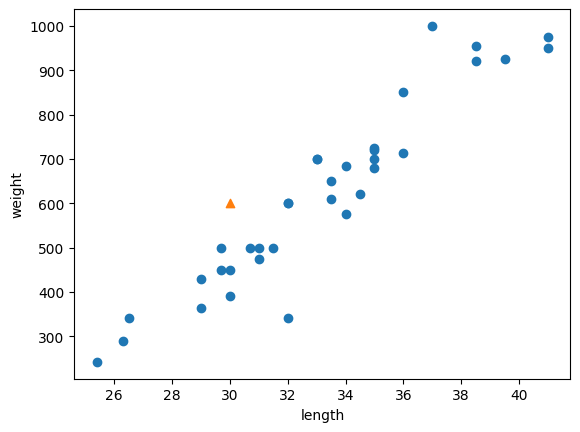

In [28]:
new = [30, 600] #새로운 데이터
plt.scatter(bream_length, bream_weight)
plt.scatter(new[0], new[1], marker='^') #그래프에 새로운 데이터 표시
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [30]:
kn.predict([new])  #무엇인지 판단

array([1])

In [32]:
if kn.predict([new])==1:
  print("도미")
else:
  print("빙어")

도미


### 하이퍼파라미터 이해
이웃의 갯수를 늘리면 결과가 좋아질까?

In [34]:
#이웃을 49개로 늘려보자
kn49 = KNeighborsClassifier(n_neighbors=49)

In [36]:
kn49.fit(fish_data, fish_target)
kn49.score(fish_data, fish_target)

0.7142857142857143

In [38]:
print(35/49) # 49개중 35개 맞춤

0.7142857142857143


### 확인 문제
도미 빙어 문제에서 이웃의 개수는 어디까지 사용가능할까?

In [39]:
kn = KNeighborsClassifier()
kn.fit(fish_data, fish_target)

for n in range(5, 50):
  #최근접 이웃 개수 설정
  kn.n_neighbors = n
  #점수 계산
  score = kn.score(fish_data, fish_target)
  # 100%정확도에 미치치 못하는 이웃 개수 출력
  if score < 1:
    print(n, score)
    break

18 0.9795918367346939
